In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter
import time, warnings
warnings.filterwarnings("ignore")
from mpl_toolkits.mplot3d import Axes3D

G = 6.67e-11   # m³ / (kg · s²)

# ══════════════════════════════════════════════════════════════════════════════
#  PRISM FORWARD MODELLING  
# ══════════════════════════════════════════════════════════════════════════════
_SIGNS = np.array([(-1)**(i+j+k) for i in range(2)
                                   for j in range(2)
                                   for k in range(2)], dtype=float)

def _slog(v):       return np.log(np.where(np.abs(v) > 1e-30, np.abs(v), 1e-30))
def _satan(y, x):   return np.arctan2(y, np.where(np.abs(x) > 1e-30, x, 1e-30))
def _r(dx, dy, dz): return np.sqrt(dx**2 + dy**2 + dz**2)

def _kernel_gzy(dx, dy, dz): return -_slog(dx+_r(dx,dy,dz))
def _block(fn, obs_x, obs_y, obs_z, px1, px2, py1, py2, pz1, pz2, scale):
    
    N, M = len(obs_x), len(px1)
    out = np.zeros((N, M))
    cx = [px1, px2]; cy = [py1, py2]; cz = [pz1, pz2]
    s = 0
    for i in range(2):
        for j in range(2):
            for k in range(2):
                dx = cx[i] - obs_x[:, None]
                dy = cy[j] - obs_y[:, None]
                dz = cz[k] - obs_z[:, None]
                out += _SIGNS[s] * fn(dx, dy, dz)
                s += 1
    return G * out * scale

def build_A_gzy(obs_x, obs_y, obs_z, px1, px2, py1, py2, pz1, pz2):

    
    B = _block(_kernel_gzy, obs_x, obs_y, obs_z, px1, px2, py1, py2, pz1, pz2, 1e9)  # E
    print(f"    tzy[E]   max={np.abs(B).max():.4e}")
    return B


# ══════════════════════════════════════════════════════════════════════════════
#   DEPTH-WEIGHTING  
# ══════════════════════════════════════════════════════════════════════════════

def build_Wm(pz_c, dx, dy, dz, z0=25, beta=3.5, alpha_s=1.0):
    
    w = 1.0 / (z0 + pz_c) ** (beta / 2.0)
    d = alpha_s * np.sqrt(dx * dy * dz) * w
    return np.maximum(d, 1e-12)


# ══════════════════════════════════════════════════════════════════════════════
# 2.4  ADAPTIVE CGLS REGULARIZATION  
# ══════════════════════════════════════════════════════════════════════════════

def acglsr(A, d_obs, wd, wm, m0=None, Nmax=50, target_phi = 1024,
           delta=0.75, m_low=-np.inf, m_high=np.inf, verbose=True):
    
    N, M = A.shape
    if m0 is None:
        m0 = np.zeros(M)

    wm_inv = 1.0 / wm

    Aw = (wd[:, None] * A) * wm_inv[None, :]
    dw = wd * (d_obs - A @ m0)

    def Qv(v, mu2):
        return Aw.T @ (Aw @ v) + mu2 * v

    q = Aw.T @ dw

    eps_trial   = 1e2
    phi_d_init  = float(np.dot(dw, dw))
    phi_m_trial = eps_trial**2 * float(np.dot(wm, wm))
    mu2         = phi_d_init / (phi_m_trial + 1e-30)

    if verbose:
        print(f"  Initial μ² = {mu2:.4e}  (from Eq. 27: phi_d/M = {phi_d_init:.4e}/{M})")

    m_k = np.zeros(M)
    mwk = wm * (m_k - m0)

    fk  = Qv(mwk, mu2) - q
    dk  = fk.copy()

    Qdk  = Qv(dk, mu2)
    denom_init = np.dot(dk, Qdk)
    tk = np.dot(dk, fk) / (denom_init + 1e-30)

    resid  = wd * (A @ m_k - d_obs)
    phi_d  = float(np.dot(resid, resid))
    phi_hist = [phi_d]

    m_best = m_k.copy()

    if verbose:
        print(f"\n  {'Iter':>5}  {'phi_d':>14}  {'mu2':>12}  {'||m||_inf':>10}")
        print("  " + "─" * 52)
        print(f"  {'0':>5}  {phi_d:>14.6e}  {mu2:>12.4e}  {np.abs(m_k).max():>10.4f}")

    for k in range(Nmax):

        mwk = mwk - tk * dk
        m_k = wm_inv * mwk + m0
        m_k = np.clip(m_k, m_low, m_high)
        m_best = m_k.copy()

        resid = wd * (A @ m_k - d_obs)
        phi_d = float(np.dot(resid, resid))
        phi_hist.append(phi_d)

        if verbose:
            print(f"  {k+1:>5}  {phi_d:>14.6e}  {mu2:>12.4e}  {np.abs(m_k).max():>10.4f}")

        if phi_d < target_phi:
            if verbose:
                print(f"\n  ✓ Converged at iteration {k+1}")
            break

        mwk = wm * (m_k - m0)
        mu2 = max(delta**2 * mu2, 1e-8)

        fk_new = Qv(mwk, mu2) - q
        beta_k = np.dot(fk_new, fk_new) / (np.dot(fk, fk) + 1e-30)
        dk_new = fk_new + beta_k * dk

        Qdk  = Qv(dk_new, mu2)
        denom = np.dot(dk_new, Qdk)
        tk = np.dot(dk_new, fk_new) / (denom + 1e-30)

        fk = fk_new
        dk = dk_new

    return m_best, phi_hist


# ══════════════════════════════════════════════════════════════════════════════
# MAIN
# ══════════════════════════════════════════════════════════════════════════════

t0 = time.time()
print("=" * 65)
print("  ACGLSR — Single-Prism Test, tzy-ONLY  ")
print("=" * 65)

# ── Observation grid 32×32 @ 50-m spacing ─────────────────────────────
sp  = 50.0   # in m
x1d = np.arange(sp/2, 1600, sp)
y1d = np.arange(sp/2, 1600, sp)
Xo, Yo  = np.meshgrid(x1d, y1d)
obs_x   = Xo.ravel()
obs_y   = Yo.ravel()
obs_z   = np.zeros(len(obs_x))
N_obs   = len(obs_x)
print(f"  Observations : {N_obs}")

# ── Prism grid 32×32×16 ──────────────────────────────────────────────
nx, ny, nz = 32, 32, 16
dx, dy, dz = 50, 50, 50
xe = np.linspace(0, 1600, nx + 1)
ye = np.linspace(0, 1600, ny + 1)
ze = np.linspace(0, 800,  nz + 1)
iz_g, iy_g, ix_g = np.meshgrid(np.arange(nz), np.arange(ny),
                                np.arange(nx), indexing='ij')
ix_g = ix_g.ravel(); iy_g = iy_g.ravel(); iz_g = iz_g.ravel()
px1 = xe[ix_g]; px2 = xe[ix_g + 1]
py1 = ye[iy_g]; py2 = ye[iy_g + 1]
pz1 = ze[iz_g]; pz2 = ze[iz_g + 1]
pz_c = 0.5 * (pz1 + pz2)
M = len(px1)
print(f"  Prisms       : {nx}×{ny}×{nz}={M}")

# ── True model: x=550m-950m, y=600m-900m, z=200-600 m ──────────────────────────
m_true = np.zeros(M)
cx = 0.5 * (px1 + px2)
cy = 0.5 * (py1 + py2)
cz = 0.5 * (pz1 + pz2)
mask = (cx >= 550) & (cx <= 950) & (cy >= 600) & (cy <= 900) & (cz >= 200) & (cz <= 600)
m_true[mask] = 1000.0  # Density contrast in kg/m3
print(f"  True cells   : {mask.sum()}")

# ── Forward model (tzy) ────────────────────────────────────────────
print("\n  Building design matrix A (tzy) …")
A = build_A_gzy(obs_x, obs_y, obs_z, px1, px2, py1, py2, pz1, pz2)
print(f"  A : {A.shape[0]}×{A.shape[1]}")

d_clean = A @ m_true
print(f"  ||d_clean|| = {np.linalg.norm(d_clean):.4e}")


# ── Add 10% zero-mean Gaussian noise ────────────────────────────────
noise_level = 0.1
rng = np.random.default_rng(123)

std_tzy = np.std(d_clean) # standard deviation of clean data
sigma_tzy = noise_level * std_tzy # standard deviation of noise

noise = rng.normal(0.0, sigma_tzy, size=N_obs)
d_obs = d_clean + noise

print(f"Clean tzy SD       = {std_tzy:.6e} E")
print(f"Noise sigma        = {sigma_tzy:.6e} E")
print(f"Realized noise SD  = {np.std(noise):.6e} E")
print(f"Realized ratio     = {np.std(noise)/std_tzy:.4f}")

wm = build_Wm(pz_c, dx, dy, dz, z0=dz/2, beta=3.95, alpha_s=0.1)

wd = np.full(N_obs, 1.0 / sigma_tzy)

# =============================================================================
# CONDITION NUMBER OF THE RAW TENSOR KERNEL
# =============================================================================
print("\n  Calculating condition number of A ...")

# Singular values of A
singular_values = np.linalg.svd(
    A,
    compute_uv=False
)
sigma_max = singular_values[0]
sigma_min = singular_values[-1]

condition_number_A = sigma_max / sigma_min

print("\n" + "=" * 65)
print("  CONDITION NUMBER — RAW tzy KERNEL")
print("=" * 65)

print(f"  Kernel shape             : {A.shape}")
print(f"  Number of observations   : {A.shape[0]}")
print(f"  Number of model cells    : {A.shape[1]}")
print(f"  Largest singular value   : {sigma_max:.6e}")
print(f"  Smallest singular value  : {sigma_min:.6e}")
print(f"  Condition number κ(A)    : {condition_number_A:.6e}")

if condition_number_A < 1e2:
    print("  Interpretation            : Well conditioned")
elif condition_number_A < 1e4:
    print("  Interpretation            : Moderately ill-conditioned")
elif condition_number_A < 1e6:
    print("  Interpretation            : Strongly ill-conditioned")
elif condition_number_A < 1e10:
    print("  Interpretation            : Severely ill-conditioned")
else:
    print("  Interpretation            : Extremely ill-conditioned")

print("=" * 65)

# =============================================================================
# CONDITION NUMBER OF THE WEIGHTED KERNEL USED BY ACGLSR
# =============================================================================
print("\n  Calculating condition number of weighted kernel ...")
wm_inv = 1.0 / wm
Aw = (
    wd[:, None] * A
) * wm_inv[None, :]

# Singular values
singular_values_w = np.linalg.svd(
    Aw,
    compute_uv=False
)
sigma_max_w = singular_values_w[0]
sigma_min_w = singular_values_w[-1]

condition_number_Aw = (
    sigma_max_w / sigma_min_w
)
print("\n" + "=" * 65)
print("  CONDITION NUMBER — WEIGHTED tzy KERNEL")
print("=" * 65)

print(f"  Weighted kernel shape    : {Aw.shape}")
print(f"  Largest singular value   : {sigma_max_w:.6e}")
print(f"  Smallest singular value  : {sigma_min_w:.6e}")
print(f"  Condition number κ(Aw)   : {condition_number_Aw:.6e}")

print("=" * 65)


# ── ACGLSR ────────────────────────────────────────────────────────────
print("\n  Running ACGLSR (tzy-only")
m_pred, phi_hist = acglsr(
    A, d_obs, wd, wm,
    m0=np.zeros(M),
    Nmax=1200, target_phi = N_obs, delta=0.75,
    m_low= 0, m_high=2000,
    verbose=True
)

d_pred  = A @ m_pred
elapsed = time.time() - t0
rms_fit = np.sqrt(np.mean((d_pred - d_obs)**2))
print(f"\n  RMS error      : {rms_fit:.8f} E")
print(f"  Min predicted density : {m_pred.min():.4f} kg/m3")
print(f"  Max predicted density : {m_pred.max():.4f} kg/m3")
print(f"  Elapsed time   : {elapsed:.1f} s")

sh  = (nz, ny, nx)
mt3 = m_true.reshape(sh)
mp3 = m_pred.reshape(sh)

  ACGLSR — Single-Prism Test, tzy-ONLY  (Chen et al. 2024, Sec. 3.1.1)
  Observations : 1024
  Prisms       : 32×32×16=16384
  True cells   : 384

  Building design matrix A (tzy) …
    tzy[E]   max=5.2603e-02
  A : 1024×16384
  ||d_clean|| = 4.5260e+02
Clean tzy SD       = 1.414221e+01 E
Noise sigma        = 1.414221e+00 E
Realized noise SD  = 1.426425e+00 E
Realized ratio     = 0.1009

  Calculating condition number of A ...

  CONDITION NUMBER — RAW tzy KERNEL
  Kernel shape             : (1024, 16384)
  Number of observations   : 1024
  Number of model cells    : 16384
  Largest singular value   : 1.896304e-01
  Smallest singular value  : 2.784651e-03
  Condition number κ(A)    : 6.809843e+01
  Interpretation            : Well conditioned

  Calculating condition number of weighted kernel ...

  CONDITION NUMBER — WEIGHTED tzy KERNEL
  Weighted kernel shape    : (1024, 16384)
  Largest singular value   : 1.484785e+02
  Smallest singular value  : 1.356603e-01
  Condition number κ(Aw

d_obs =
 [ 0.32396917  1.47477734  4.12539426 ... -1.74012037 -2.14052717
  0.8866187 ]

 d_pred =
 [ 2.90778201  3.36617867  3.84144002 ... -2.50845571 -2.19594519
 -1.91346377]

 d_obs maximum = 46.00113871720703
d_pred maximum = 44.855588438919455

 d_obs minimum = -46.29189294827474
d_pred minimum = -44.38219859010692

 d_obs mean = -0.1664885908963205
d_pred mean = -0.17098416032992247

Zres =
 [[-2.58381284 -1.89140133  0.28395425 ... -1.17670746 -1.53357685
  -2.61177827]
 [ 1.47321681 -3.19578645 -0.69969682 ... -0.90648195 -0.561164
  -0.82913361]
 [-1.95598412  2.07119456  0.74813833 ... -0.08292977  1.94694203
  -1.7197607 ]
 ...
 [-1.43088089 -0.87608906 -1.76919859 ...  0.42299124 -1.80376981
   1.98675956]
 [-1.72496104  1.22604775  2.62118009 ... -0.84915591  1.62717448
   1.72092528]
 [ 0.50356782  1.64976844  1.29377555 ...  0.76833534  0.05541802
   2.80008247]]

Zres maximum = 5.118177826310706
Zres minimum = -4.734653272102314
Zres mean = 0.0044955694336008545
RMS r

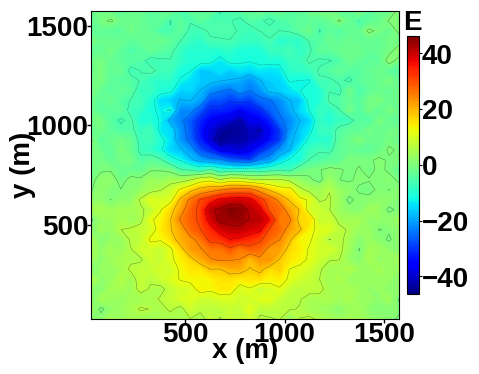

Saved: Fig01_Observed_tzy.png


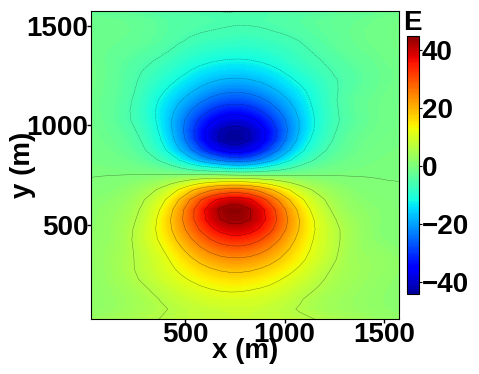

Saved: Fig02_Predicted_tzy.png


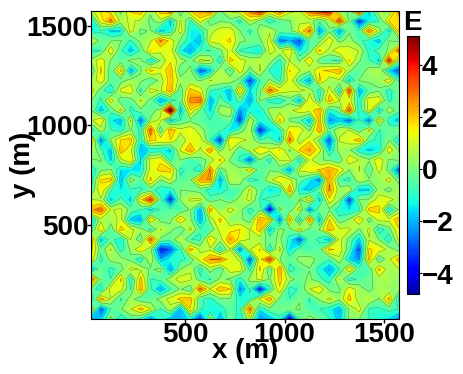

Saved: Fig03_Residual_tzy.png


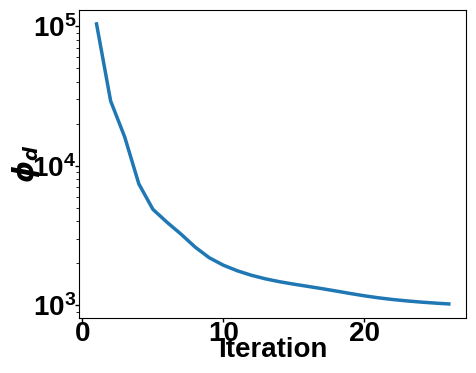

Saved: Fig04_Convergence.png
Convergence data saved: /home/rahul/MTP/INVERSION/ACGLSR_Method/Single_Prism_Model/Single_Prism_Combined_Convergence_all_components/S_P_tzy_Conver_Data.xlsx


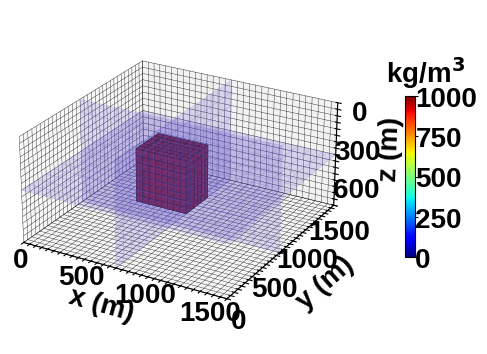

Saved: Fig05_True_3D_Density_Model.png


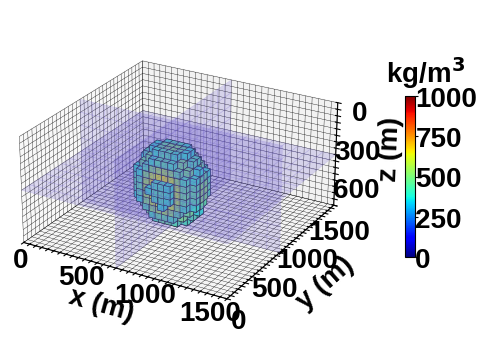

Saved: Fig06_Predicted_3D_Density_Model.png


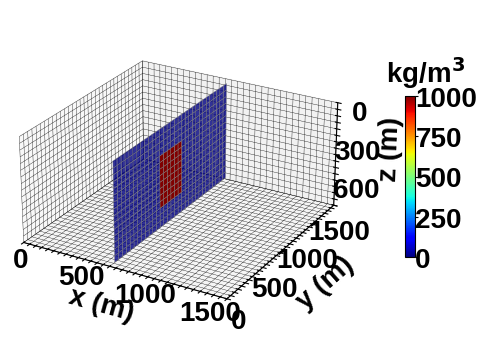

Saved: Fig07_True_YZ_x750.png


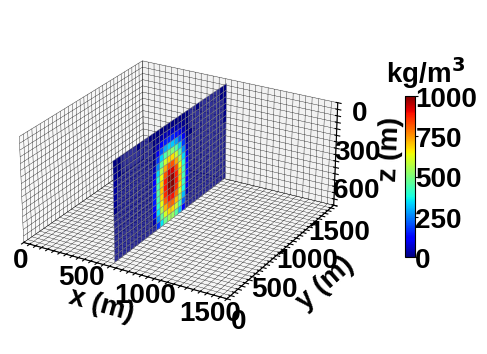

Saved: Fig08_Predicted_YZ_x750.png


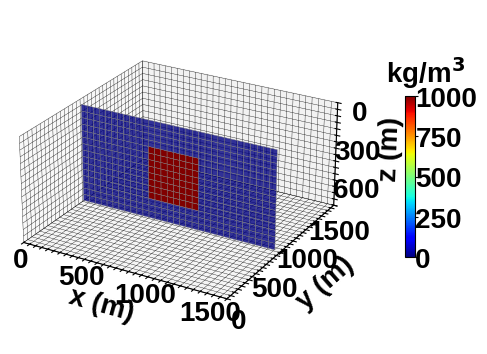

Saved: Fig09_True_XZ_y750.png


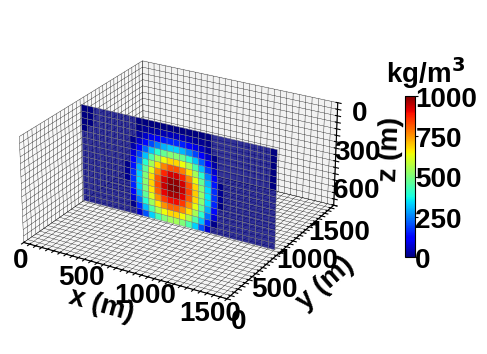

Saved: Fig10_Predicted_XZ_y750.png


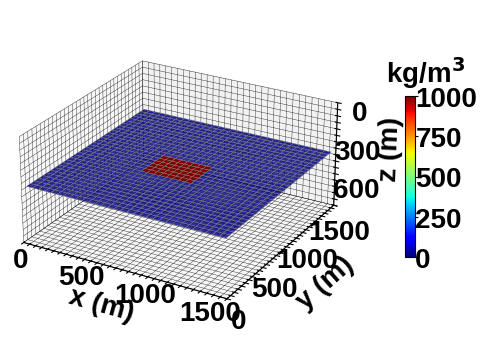

Saved: Fig11_True_XY_z400.png


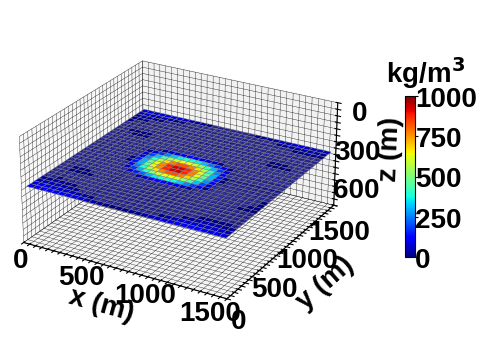

Saved: Fig12_Predicted_XY_z400.png

ALL 12 FIGURES SAVED SUCCESSFULLY
PNG resolution: 600 DPI
NO TITLES ON FIGURES


In [3]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, MaxNLocator
from PIL import Image, ImageChops

# ── Global publication settings ──────────────────────────────────────
BG=AX="white"; TC="black"; DPI=600
mpl.rcParams.update({
    "font.family":"Liberation Sans","font.size":20,
    "axes.labelsize":20,"axes.titlesize":20,"xtick.labelsize":20,"ytick.labelsize":20,
    "legend.fontsize":20,"figure.facecolor":"white",
    "axes.facecolor":"white","savefig.dpi":600,
    "savefig.facecolor":"white","axes.edgecolor":"black",
    "axes.linewidth":.8,"xtick.color":"black","ytick.color":"black",
    "text.color":"black","axes.labelcolor":"black",
    "ps.fonttype":42,"font.weight":"bold","axes.labelweight":"bold",
    "axes.titleweight":"bold"
})
# ── Axis style ───────────────────────────────────────────────────────
def _style(ax,xl="",yl=""):
    ax.set_facecolor(AX); ax.tick_params(axis="both",colors=TC,direction="out",width=1.0,length=3.0,pad=-1.0)
    ax.set_xlabel(xl,color=TC,labelpad=-7.0); ax.set_ylabel(yl,color=TC,labelpad=-7.0)
    for sp in ax.spines.values(): sp.set_edgecolor(TC); sp.set_linewidth(.8)

# ── Publication colorbar ─────────────────────────────────────────────
def _publication_colorbar(cf,ax,fig,title,scientific=False):
    cb=fig.colorbar(cf,ax=ax,shrink=0.84,pad=.02,aspect=21)
    cb.ax.set_title(title,color=TC,y=0.99,x=0.5)
    cb.locator=MaxNLocator(nbins=8,steps=[1,2,2.5,5,10]) # Clean tick spacing
    cb.ax.tick_params(colors=TC,direction="out",width=.8,length=2,pad=0.0)
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8)
    fmt=ScalarFormatter(useMathText=False); fmt.set_scientific(scientific); fmt.set_useOffset(False)
    cb.formatter=fmt; cb.update_ticks(); return cb

def save_fig(fig,filename,tight=True):
    kw={"dpi":600,"facecolor":BG,"pad_inches":0}
    if tight:kw["bbox_inches"]="tight"
    fig.savefig(filename,**kw)
    plt.show()
    plt.close(fig)
    crop_white_margin(filename,padding=0)
    print("Saved:",filename)

def crop_white_margin(filename,padding=0):
    img=Image.open(filename).convert("RGB")
    bbox=ImageChops.difference(img,Image.new("RGB",img.size,"white")).getbbox()
    if bbox:
        x0,y0,x1,y1=bbox
        img.crop((max(0,x0-padding),max(0,y0-padding),
                  min(img.width,x1+padding),min(img.height,y1+padding))
                ).save(filename,dpi=(DPI,DPI))
        
# ── Observation grid ─────────────────────────────────────────────────
ng=int(np.sqrt(N_obs)); X=obs_x.reshape(ng,ng); Y=obs_y.reshape(ng,ng)
Zobs=d_obs.reshape(ng,ng); Zpred=d_pred.reshape(ng,ng); Zres=Zobs-Zpred
vmin=min(Zobs.min(),Zpred.min()); vmax=max(Zobs.max(),Zpred.max()); rmax=np.max(np.abs(Zres))

# ── General 2-D tzy plot ─────────────────────────────────────────────
def plot_tzy(data,filename,label,vmin,vmax):
    fig,ax=plt.subplots(figsize=(5,4)); fig.patch.set_facecolor(BG)
    cf=ax.contourf(X,Y,data,levels=150,cmap="jet",vmin=vmin,vmax=vmax)
    ax.contour(X,Y,data,levels=15,colors="k",linewidths=.3,alpha=.5)
    _style(ax,"x (m)","y (m)"); ax.set_aspect("equal"); _publication_colorbar(cf,ax,fig,"E")
    save_fig(fig,filename)
    
# ============================================================
# Tensor and residual statistics
# ============================================================
# Observed and predicted tensor
print("d_obs =\n", d_obs)
print("\n d_pred =\n", d_pred)

# Maximum values
print("\n d_obs maximum =", np.max(d_obs))
print("d_pred maximum =", np.max(d_pred))

# Minimum values
print("\n d_obs minimum =", np.min(d_obs))
print("d_pred minimum =", np.min(d_pred)) 

# Mean values
print("\n d_obs mean =", np.mean(d_obs))
print("d_pred mean =", np.mean(d_pred))

# Residual tensor: observed - predicted
print("\nZres =\n", Zres)

# Residual statistics
print("\nZres maximum =", np.max(Zres))
print("Zres minimum =", np.min(Zres))
print("Zres mean =", np.mean(Zres))

# RMS residual
rms = np.sqrt(np.mean(Zres**2))
print("RMS residual =", rms)

# ── Figures 1–3: observed, predicted and residual tzy ────────────────
plot_tzy(Zobs,"Fig01_Observed_tzy.png","tzy (E)",vmin,vmax)
plot_tzy(Zpred,"Fig02_Predicted_tzy.png","tzy (E)",vmin,vmax)
plot_tzy(Zres,"Fig03_Residual_tzy.png","tzy residual (E)",-rmax,rmax)

# ── Figure 4: convergence ────────────────────────────────────────────
def plot_convergence(phi,filename):
    fig,ax=plt.subplots(figsize=(5,4))
    ax.semilogy(np.arange(1,len(phi)+1),phi,lw=2.5)
    _style(ax,"Iteration",r"$\phi_d$"); save_fig(fig,filename)

def save_convergence_excel(phi,filename):
    pd.DataFrame({"Iteration":np.arange(1,len(phi)+1),"phi_d":phi}).to_excel(filename,index=False)
    print("Convergence data saved:",filename)

plot_convergence(phi_hist,"Fig04_Convergence.png")

convergence_file="/home/rahul/MTP/INVERSION/ACGLSR_Method/Single_Prism_Model/Single_Prism_Combined_Convergence_all_components/S_P_tzy_Conver_Data.xlsx"
save_convergence_excel(phi_hist,convergence_file)

# ── True prism bounds ────────────────────────────────────────────────
px_lo,px_hi=550.0,950.0; py_lo,py_hi=600.0,900.0; pz_lo,pz_hi=200.0,600.0
clim=(0,1000)

# ── Common 3-D settings ──────────────────────────────────────────────
cmap_3d=plt.cm.jet; norm=plt.Normalize(vmin=0,vmax=1000); X3,Y3,Z3=np.meshgrid(xe,ye,ze,indexing="ij")

# ── 3-D axis settings: 50 m gridlines, labels every 200/100 m ───────
def setup_3d(ax):
    ax.set_xlim(0,1600); ax.set_ylim(0,1600); ax.set_zlim(800,0)
    xg=np.arange(0,1601,50); yg=np.arange(0,1601,50); zg=np.arange(0,801,50)
    ax.set_xticks(xg); ax.set_yticks(yg); ax.set_zticks(zg)
    ax.set_xticklabels([str(v) if v%500==0 else "" for v in xg])
    ax.set_yticklabels([str(v) if v%500==0 else "" for v in yg])
    ax.set_zticklabels([str(v) if v%300==0 else "" for v in zg])
    
    ax.set_xlabel("x (m)",color=TC,labelpad=0.0); ax.set_ylabel("y (m)",color=TC,labelpad=5)
    ax.set_zlabel("z (m)",color=TC,labelpad=2.0)
    
    ax.tick_params(axis="x",colors=TC,direction="out",
                   width=.7,length=3,pad=-5.0)
    ax.tick_params(axis="y",colors=TC,direction="out",
                   width=.7,length=3,pad=-1.0)
    ax.tick_params(axis="z",colors=TC,direction="out",
                   width=.7,length=3,pad=1.0) 
    for a in [ax.xaxis,ax.yaxis,ax.zaxis]:
        a._axinfo["grid"]["color"]="black"; a._axinfo["grid"]["linewidth"]=.25; a._axinfo["grid"]["linestyle"]="-"
    ax.set_facecolor(AX); ax.set_box_aspect((1600,1600,800)); ax.view_init(elev=25,azim=-60)

# ── Transparent density boundaries ───────────────────────────────────
def add_density_boundaries(ax,xe,ye,ze,alpha=.2):
    Y,Z=np.meshgrid(ye,ze); X=np.full_like(Y,750,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,edgecolor="slateblue",linewidth=.35,rstride=2,cstride=2,shade=False)
    X,Z=np.meshgrid(xe,ze); Y=np.full_like(X,750,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,edgecolor="slateblue",linewidth=.35,rstride=2,cstride=2,shade=False)
    X,Y=np.meshgrid(xe,ye); Z=np.full_like(X,400,dtype=float)
    ax.plot_surface(X,Y,Z,color="slateblue",alpha=alpha,edgecolor="slateblue",linewidth=.35,rstride=2,cstride=2,shade=False)

# ── 3-D density colorbar ─────────────────────────────────────────────
def density_3d_colorbar(fig,ax,cmap,norm):
    sm=mpl.cm.ScalarMappable(cmap=cmap,norm=norm); sm.set_array([])
    cb=fig.colorbar(sm,ax=ax,shrink=.42,pad=0.13,aspect=16)
    cb.ax.set_title(r"kg/m$^3$",color=TC,y=1.03,x=2.0)
    cb.set_ticks(np.arange(0,1001,250))
    cb.ax.tick_params(colors=TC,direction="out",width=.8,length=2,pad=-2.0)
    cb.outline.set_edgecolor(TC); cb.outline.set_linewidth(.8); return cb

# ── Function for 3-D model ───────────────────────────────────────────
def plot_3d_model(arr,filename,threshold):
    fig=plt.figure(figsize=(6,5)); fig.patch.set_facecolor(BG); ax=fig.add_subplot(111,projection="3d")
    filled=arr>threshold; fc=np.zeros((*arr.shape,4)); fc[filled]=cmap_3d(norm(arr[filled]))
    ax.voxels(X3,Y3,Z3,filled.transpose(2,1,0),facecolors=fc.transpose(2,1,0,3),edgecolor="black",linewidth=0.4,alpha=1.0,shade=False)
    add_density_boundaries(ax,xe,ye,ze,alpha=.2); setup_3d(ax); density_3d_colorbar(fig,ax,cmap_3d,norm)
    save_fig(fig,filename)
# ── Figure 5: true 3-D model ─────────────────────────────────────────
plot_3d_model(mt3,"Fig05_True_3D_Density_Model.png",.05*1000)

# ── Figure 6: predicted 3-D model ───────────────────────────────────
plot_3d_model(mp3,"Fig06_Predicted_3D_Density_Model.png",.4*1000)

# ── True prism boundary on predicted density slices ──────────────────
def add_true_prism_boundary(ax,x_slice=None,y_slice=None,z_slice=None):
    if x_slice is not None:                                      # YZ: x = constant
        ax.plot([x_slice]*5,[py_lo,py_hi,py_hi,py_lo,py_lo],[pz_lo,pz_lo,pz_hi,pz_hi,pz_lo],
                color="black",linewidth=1.5,linestyle="--",zorder=10)
    elif y_slice is not None:                                    # XZ: y = constant
        ax.plot([px_lo,px_hi,px_hi,px_lo,px_lo],[y_slice]*5,[pz_lo,pz_lo,pz_hi,pz_hi,pz_lo],
                color="black",linewidth=1.5,linestyle="--",zorder=10)
    elif z_slice is not None:                                    # XY: z = constant
        ax.plot([px_lo,px_hi,px_hi,px_lo,px_lo],[py_lo,py_lo,py_hi,py_hi,py_lo],[z_slice]*5,
                color="black",linewidth=1.5,linestyle="--",zorder=10)

# ── Function for individual density slice ────────────────────────────
def plot_density_slice(model3d,x_slice=None,y_slice=None,z_slice=None,filename="",show_boundary=False):
    fig=plt.figure(figsize=(6,5)); fig.patch.set_facecolor(BG); ax=fig.add_subplot(111,projection="3d")
    xc=.5*(xe[:-1]+xe[1:]); yc=.5*(ye[:-1]+ye[1:]); zc=.5*(ze[:-1]+ze[1:])
    if x_slice is not None:
        ix=np.argmin(np.abs(xc-x_slice)); Y,Z=np.meshgrid(yc,zc); X=np.full_like(Y,xc[ix]); rho=model3d[:,:,ix]
    elif y_slice is not None:
        iy=np.argmin(np.abs(yc-y_slice)); X,Z=np.meshgrid(xc,zc); Y=np.full_like(X,yc[iy]); rho=model3d[:,iy,:]
    elif z_slice is not None:
        iz=np.argmin(np.abs(zc-z_slice)); X,Y=np.meshgrid(xc,yc); Z=np.full_like(X,zc[iz]); rho=model3d[iz,:,:]
    else: plt.close(fig); return
    fc=cmap_3d(norm(rho)); fc[...,3]=np.where(np.abs(rho)>1e-12,1.0,.8)
    ax.plot_surface(X,Y,Z,facecolors=fc,rstride=1,cstride=1,linewidth=.3,edgecolor="gray",shade=False,antialiased=True)
    #if show_boundary: add_true_prism_boundary(ax,x_slice=x_slice,y_slice=y_slice,z_slice=z_slice)
    setup_3d(ax); density_3d_colorbar(fig,ax,cmap_3d,norm)
    save_fig(fig,filename)

# ── Figures 7–12: true/predicted YZ, XZ and XY slices ────────────────
plot_density_slice(mt3,x_slice=750,filename="Fig07_True_YZ_x750.png")
plot_density_slice(mp3,x_slice=750,filename="Fig08_Predicted_YZ_x750.png",show_boundary=True)
plot_density_slice(mt3,y_slice=750,filename="Fig09_True_XZ_y750.png")
plot_density_slice(mp3,y_slice=750,filename="Fig10_Predicted_XZ_y750.png",show_boundary=True)
plot_density_slice(mt3,z_slice=400,filename="Fig11_True_XY_z400.png")
plot_density_slice(mp3,z_slice=400,filename="Fig12_Predicted_XY_z400.png",show_boundary=True)
# =====================================================================
# COMPLETE
# =====================================================================
print("\n==============================================")
print("ALL 12 FIGURES SAVED SUCCESSFULLY")
print("==============================================")
print("PNG resolution: 600 DPI")
print("NO TITLES ON FIGURES")
print("==============================================")

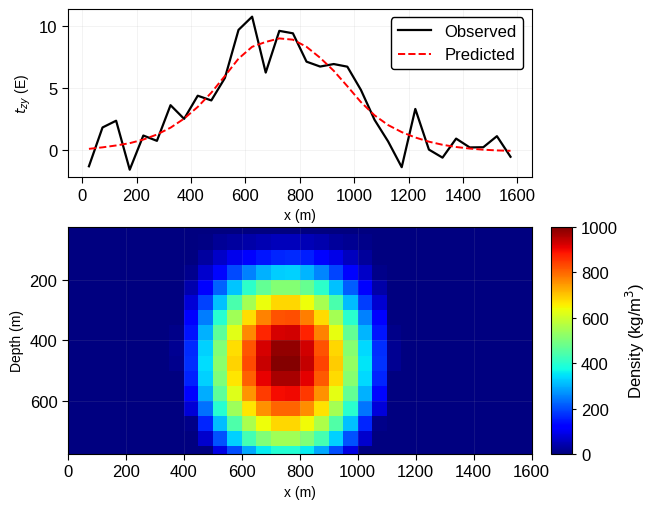

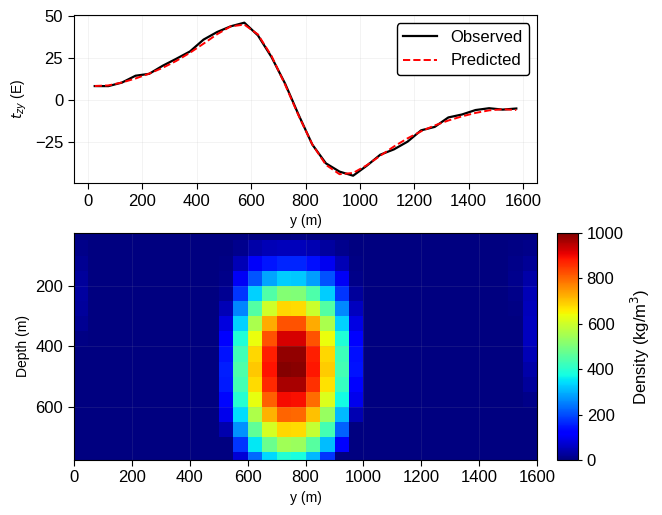

In [5]:
# =====================================================================
# 14–15. EW/NS Tzy PROFILE + DENSITY SECTION
# =====================================================================
def plot_tzy_profile_density_section(direction="EW", coordinate=750,
                                     filename="tzy_Profile_Density_Section.png"):

    # --- Model cell centres ---
    xc, yc, zc = [(a[:-1] + a[1:]) / 2 for a in (xe, ye, ze)]

    # --- Select profile and density section ---
    if direction.upper() == "EW":
        i = np.argmin(abs(Y[:, 0] - coordinate))
        profile, obs, pred = X[i], Zobs[i], Zpred[i]
        pd.DataFrame({
            "x (m)": profile,
            "Observed tzy (E)": obs,
            "Predicted tzy (E)": pred
        }).to_excel("XZ_tzy_Profile_y750.xlsx", index=False)
        j = np.argmin(abs(yc - coordinate))
        section, Xsec, Zsec, xlabel = mp3[:, j, :], *np.meshgrid(xc, zc), "x (m)"

    elif direction.upper() == "NS":
        i = np.argmin(abs(X[0] - coordinate))
        profile, obs, pred = Y[:, i], Zobs[:, i], Zpred[:, i]
        pd.DataFrame({
            "y (m)": profile,
            "Observed tzy (E)": obs,
            "Predicted tzy (E)": pred
        }).to_excel("YZ_tzy_Profile_x750.xlsx", index=False)
        j = np.argmin(abs(xc - coordinate))
        section, Xsec, Zsec, xlabel = mp3[:, :, j], *np.meshgrid(yc, zc), "y (m)"

    else:
        raise ValueError("direction must be 'EW' or 'NS'")

    # --- Create equal-width panels ---
    fig = plt.figure(figsize=(6, 5))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.35],
                          width_ratios=[1, .045], hspace=.25, wspace=.08)
    ax1, ax2, cax = (fig.add_subplot(gs[0, 0]),
                     fig.add_subplot(gs[1, 0]),
                     fig.add_subplot(gs[1, 1]))
    fig.patch.set_facecolor(BG)

    # --- (a) Tzy profile ---
    ax1.plot(profile, obs, "k", lw=1.6, label="Observed")
    ax1.plot(profile, pred, "r--", lw=1.4, label="Predicted")
    _style(ax1, xlabel, r"$t_{zy}$ (E)")
    ax1.tick_params(axis="both", labelsize=12)
    ax1.grid(True, lw=.4, alpha=.25)
    ax1.legend(loc="upper right", frameon=True, framealpha=1,
               edgecolor="black", fontsize=12)

    # --- (b) Density section ---
    pcm = ax2.pcolormesh(Xsec, Zsec, section, cmap="jet",
                         vmin=0, vmax=1000, shading="auto")
    ax2.set_ylim(zc.max(), zc.min())
    _style(ax2, xlabel, "Depth (m)")
    ax2.tick_params(axis="both", labelsize=12)
    ax2.grid(True, lw=.4, alpha=.20)

    # --- Density colorbar ---
    cb = fig.colorbar(pcm, cax=cax)
    cb.set_label(r"Density (kg/m$^3$)", fontsize=12, color=TC)
    cb.ax.tick_params(labelsize=12, colors=TC,
                      direction="out", width=.8, length=3)
    cb.outline.set_edgecolor(TC)
    cb.outline.set_linewidth(.8)

    # --- Save and display ---
    fig.subplots_adjust(left=.10, right=.94, top=.97, bottom=.08)
    fig.savefig(filename, dpi=600, bbox_inches="tight", facecolor=BG)
    plt.show()
    plt.close(fig)
# =====================================================================
# FIGURE 15 — EW (XZ), y = 750 m
# =====================================================================
plot_tzy_profile_density_section(
    "EW", 750, "Fig15_EW_XZ_tzy_Profile_Density_Section_y750.png"
)
# =====================================================================
# FIGURE 16 — NS (YZ), x = 750 m
# =====================================================================
plot_tzy_profile_density_section(
    "NS", 750, "Fig16_NS_YZ_tzy_Profile_Density_Section_x750.png"
)